In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('/kaggle/input/stroke-prediction-dataset/healthcare-dataset-stroke-data.csv')
df.head(5)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


#### 'ID' ,A column of numbers representing each person's number in the data doesn't represent anything except that it might help us determine if there are duplicate entries or not.

#### 'Gender' ,A column representing the person's gender type; we will remove the "other" values from it.

#### 'hypertension' ,A column representing people with high blood pressure: 0 means no high blood pressure, and 1 means high blood pressure.

#### 'heart_disease' ,A column representing people with heart disease: 0 means no disease, and 1 means diseased.

#### 'ever_married' ,A column representing whether people are married or not, containing the values ​​"yes" or "no".

#### 'work_type' ,A column representing each person's job type. Based on the first 5 columns of the table, there are two types: Private and Self-Employed. We will see later if there are other types.

#### 'Residence_type' ,A column representing each person's place of residence: whether they live in the city (Urban)or the countryside(Rural).

#### 'bmi' ,A column representing the mass of an object

### 'smoking_status' ,A column showing whether a person is a smoker or not, and whether one person in their family smokes. 

In [3]:
df.shape

(5110, 12)

## We have 5110 cases (rows) and 12 features (columns).

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


#### All columns has non NAN except for 'bmi' column, We might fill it in with mean, but let's find out what percentage it represents of all rows.

In [5]:
(df['bmi'].isna().sum() / len(df)*100).round(2)

np.float64(3.93)

## 3.96% of the rows are empty of BMI values. We can delete these rows and it won't have much of an impact, or we can refill them.

In [6]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


### We can observe that there are outlier values ​​in avg_glucose_level	and bmi cols

In [7]:
df['stroke'].value_counts() 

stroke
0    4861
1     249
Name: count, dtype: int64

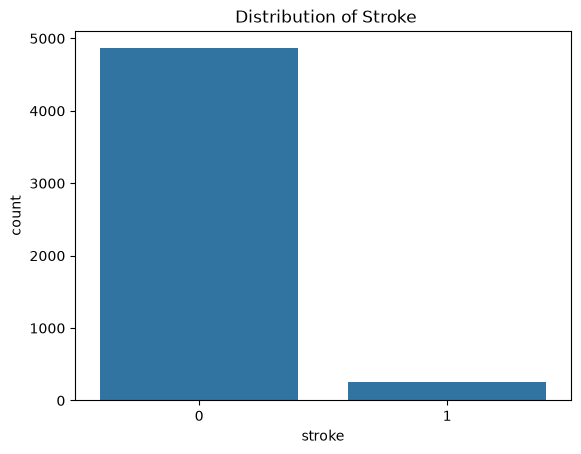

In [8]:
sns.countplot(x='stroke',data=df)
plt.title(' Distribution of Stroke')
plt.show()

In [9]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [10]:
for_countplot = ['gender','work_type','smoking_status']
for col in for_countplot:
    x= df.groupby(col)['stroke'].mean()
    print(f'{col} : {x}')
    print()


gender : gender
Female    0.047094
Male      0.051064
Other     0.000000
Name: stroke, dtype: float64

work_type : work_type
Govt_job         0.050228
Never_worked     0.000000
Private          0.050940
Self-employed    0.079365
children         0.002911
Name: stroke, dtype: float64

smoking_status : smoking_status
Unknown            0.030440
formerly smoked    0.079096
never smoked       0.047569
smokes             0.053232
Name: stroke, dtype: float64



## These numbers correspond to the orange column in the diagram.

###### gender : gender

###### Female    0.047094

###### Male      0.051064
### From the gender column, there were two types because we will remove the third category... 4.7% of women and 5.1% of men suffered a stroke... This is also what the orange column represents in the countplot diagram because it represents the value 1 within hue='stroke'

---------------

###### work_type : work_type
###### Govt_job         0.050228
###### Never_worked     0.000000
###### Private          0.050940
###### Self-employed    0.079365
###### children         0.002911

### Within the work_type column, there were 5 categories, and these numbers represent what percentage of these categories suffered a stroke.

-------------------------------------

###### smoking_status : smoking_status
###### Unknown            0.030440
###### formerly smoked    0.079096
###### never smoked       0.047569
###### smokes             0.053232

#### Within the smoking_status column, there were 4 categories, and these numbers represent what percentage of these categories suffered a stroke.

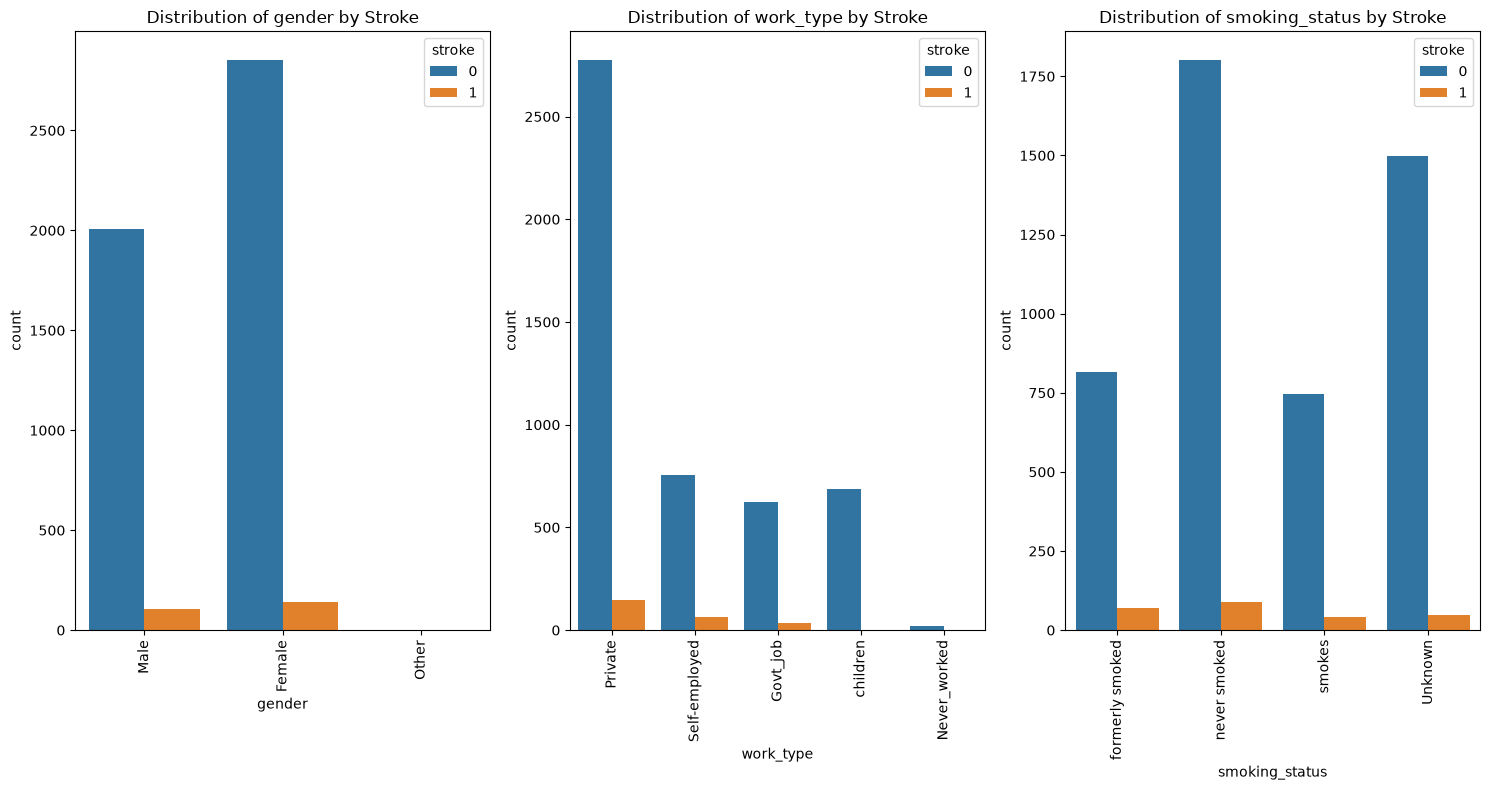

In [11]:
for_countplot = ['gender','work_type','smoking_status']
plt.figure(figsize=(15,8))
for i , col in enumerate(for_countplot):
    plt.subplot(1,3,i+1)
    sns.countplot(x=col , hue='stroke',data=df)
    plt.xticks(rotation=90)
    plt.title(f'Distribution of {col} by Stroke')
plt.tight_layout()
plt.show()

In [12]:
df['gender'].value_counts()

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

In [13]:
df=df[(df['gender']=='Female') | (df['gender']=='Male')]
#df=df[df['gender']!= 'Other']

In [14]:
df['gender'].value_counts()

gender
Female    2994
Male      2115
Name: count, dtype: int64

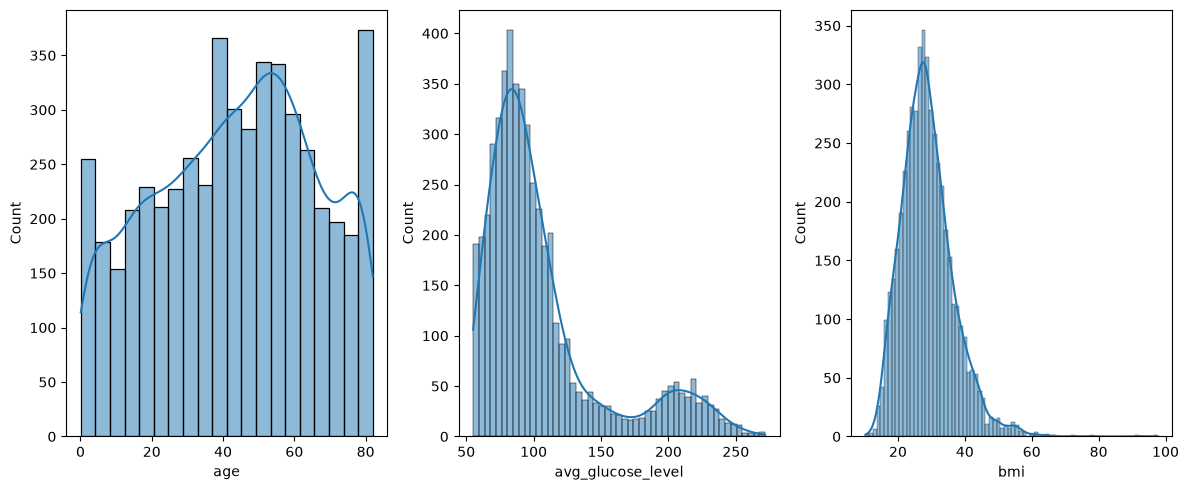

In [15]:
for_histogram=['age','avg_glucose_level','bmi']
plt.figure(figsize=(12,5))
for i, col in enumerate(for_histogram):
    plt.subplot(1,3,i+1)
    sns.histplot(x=col , data=df , kde=True)

plt.tight_layout()
plt.show()

### From the distribution we can see that:

#### 'age' ,The ages don't show anything special, most age ranges have more than 150 people. People above 80, people in the late 30s and early 40s, and people in the 50s are a little more than the other age ranges. The high bar at the end is because the max age in the data is 82, so all the old people are collected in the last bar.

#### 'avg_glucose_level' ,Most of the data is between 60 and 130, but there is a second small peak between 180 and 240. This maybe a group of people with high glucose level (diabetes), so we must be careful before we remove them as outliers.

#### 'bmi' ,Most of the data is between 18 and 40, and the peak is around 28. There is a tail pulling the line to the right until 100, maybe these are outlier values.

In [16]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [17]:
numeric_cols = df.select_dtypes(include='number').drop(columns=['id']).columns


In [18]:
corr = df[numeric_cols].corr()

<Axes: >

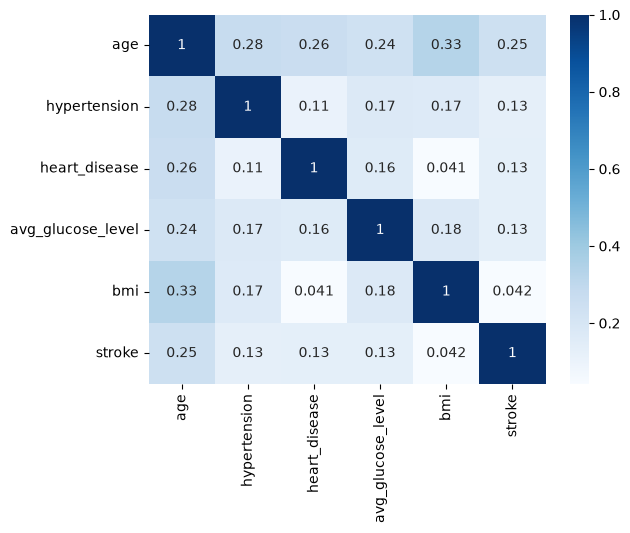

In [19]:
sns.heatmap(corr,annot=True,cmap='Blues')

----------------------


## Another easy way to read the correlation

In [20]:
corr2 = df[numeric_cols].corr()[['stroke']].sort_values('stroke',ascending=False)

<Axes: >

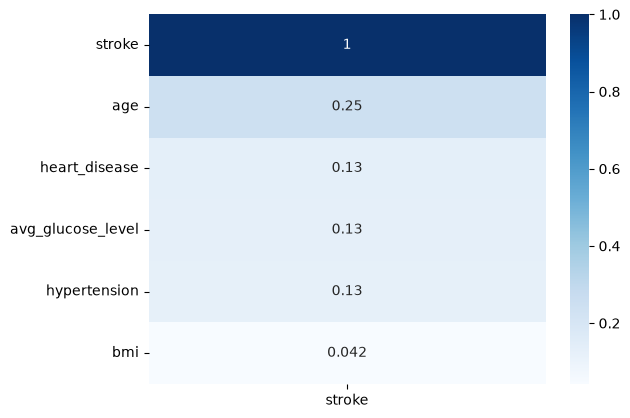

In [21]:
sns.heatmap(corr2,annot=True,cmap='Blues')

## Age has a strong effect on stroke.

In [22]:
df.isna().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

## 201 rows do not contain a BMI value, and this is what we discovered initially.

In [23]:
df['bmi']=df['bmi'].fillna(df['bmi'].median())

In [24]:
df['bmi'].isna().sum()

np.int64(0)

In [25]:
df.duplicated().sum()

np.int64(0)

In [26]:
df.drop(columns='id',inplace=True)
df.head()

C:\Users\amroa\AppData\Local\Temp\ipykernel_21396\2723557270.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns='id',inplace=True)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


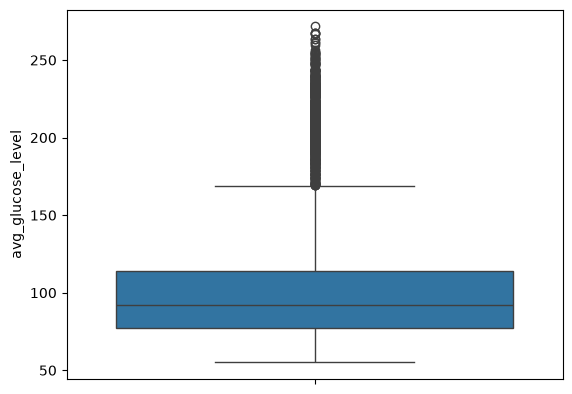

In [27]:
sns.boxplot(y='avg_glucose_level', data=df)
plt.show()

#### Here we must ask a question: Are all these circles outliers? Is it possible for a diabetic person to have a blood sugar level above 160?
#### Yes, it's possible, and these values ​​are real, not wrong.

In [28]:
(df['avg_glucose_level'] > 160).sum()

np.int64(668)

In [29]:
((df['avg_glucose_level'] > 160).sum()) /len(df)*100

np.float64(13.074965746721473)

### 13% of cases have blood sugar levels above 160, which means it's not a data entry error.

In [30]:
(df[df['avg_glucose_level'] > 160]['stroke'].mean()).round(2)

np.float64(0.13)

### Of all the people whose blood sugar is above 160, 13% have had a stroke.

In [31]:
((df[df['stroke']==1]['avg_glucose_level'] > 160).mean()).round(2)

np.float64(0.36)

### Of all the people who had a stroke, 36% had blood sugar levels above 160.

# The values ​​that appeared as outliers are very important in influencing the occurrence of a stroke, so we will leave them and will not delete them.

In [32]:
df['avg_glucose_level'].skew().round(2)

np.float64(1.57)

In [33]:
df['avg_glucose_level']=np.log1p(df['avg_glucose_level'])

In [34]:
df['avg_glucose_level'].skew().round(2)

np.float64(0.89)

#### Instead of removing them, we used log1p on avg_glucose_level to make the high values closer to the rest. The skew became 0.89, and there are still some outliers, but they are fewer and closer to the other values.

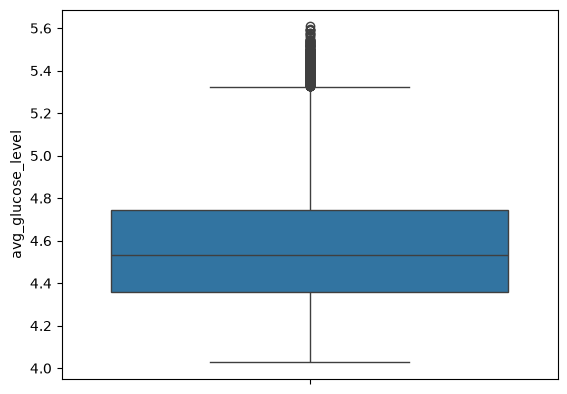

In [35]:
sns.boxplot(y='avg_glucose_level', data=df)
plt.show()

------------------------------------------

------------------------------------------

### Doing the encoding before the split can sometimes cause data leakage, so I perform the scaling, SMOTENC, and encoding steps together after the split, using ColumnTransformer and a Pipeline from imblearn.

### I always use cross validation and grid search, and doing scaling and SMOTE before cross validation will leak data, because they will be done on all the training data before it is divided into folds. So the new rows from SMOTE and the scaling values will include information from the fold that is used for testing. The Pipeline solves this, because it does these steps inside each fold separately.

In [36]:
df = df.reset_index(drop=True)
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,5.436731,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,5.314240,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,4.672081,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,5.148831,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,5.165471,24.0,never smoked,1


In [37]:
X=df.drop(columns='stroke')
y=df['stroke']

In [38]:
from sklearn.model_selection import train_test_split

In [39]:
X_train,X_test,y_train,y_test=train_test_split(X,y,stratify=y,test_size=0.2,random_state=42)

In [40]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(4087, 10) (1022, 10) (4087,) (1022,)


In [41]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,5.436731,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,5.314240,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,4.672081,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,5.148831,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,5.165471,24.0,never smoked,1


In [42]:
numeric_cols=['age','avg_glucose_level','bmi']
cat_cols=df.select_dtypes(include='object').columns

C:\Users\amroa\AppData\Local\Temp\ipykernel_21396\3372058377.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols=df.select_dtypes(include='object').columns


In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler , OneHotEncoder
from imblearn.over_sampling import  SMOTENC,SMOTE

In [44]:
scalle_step =ColumnTransformer([
    ('Scalling',StandardScaler(),numeric_cols),
],
remainder='passthrough',
verbose_feature_names_out=False
).set_output(transform='pandas')
X_train_scaled = scalle_step.fit_transform(X_train)
X_train_scaled.head()

,age,avg_glucose_level,bmi,gender,hypertension,heart_disease,ever_married,work_type,Residence_type,smoking_status
845,0.209397,-0.988690,0.549234,Female,0,0,Yes,Private,Urban,never smoked
3744,-0.629845,-0.443690,-0.988900,Female,0,0,No,Private,Urban,never smoked
4183,-0.364822,0.531189,-0.769166,Female,0,0,Yes,Private,Rural,never smoked
3409,-0.232310,0.268394,0.497532,Male,0,0,Yes,Private,Rural,never smoked
284,-1.292405,-0.505562,0.355351,Male,0,0,No,Govt_job,Urban,Unknown


In [45]:
encoding_step =ColumnTransformer([
    ('encodind',OneHotEncoder(handle_unknown='ignore',drop='if_binary',sparse_output=False),cat_cols),
],
remainder='passthrough'
).set_output(transform='pandas')



In [46]:
X_train_encoded = encoding_step.fit_transform(X_train)
X_train_encoded.head()

,encodind__gender_Male,encodind__ever_married_Yes,encodind__work_type_Govt_job,encodind__work_type_Never_worked,encodind__work_type_Private,encodind__work_type_Self-employed,encodind__work_type_children,encodind__Residence_type_Urban,encodind__smoking_status_Unknown,encodind__smoking_status_formerly smoked,encodind__smoking_status_never smoked,encodind__smoking_status_smokes,remainder__age,remainder__hypertension,remainder__heart_disease,remainder__avg_glucose_level,remainder__bmi
845,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,48.0,0,0,4.251491,33.1
3744,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,29.0,0,0,4.444884,21.2
4183,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,35.0,0,0,4.790820,22.9
3409,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,38.0,0,0,4.697567,32.7
284,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,14.0,0,0,4.422929,31.6


In [47]:
y_train.value_counts()

stroke
0    3888
1     199
Name: count, dtype: int64

### The percentage of those who suffered a stroke in the data is very small compared to those who did not suffer a stroke.
### SMOTE will create new rows, and these rows will have values between two existing values. This is a problem in categorical columns, because there is nothing called 0.4 married, and there is nothing called residence type 0.5 or smoking status 0.7. So there is another thing called SMOTENC that does what SMOTE does, but it separates between the numerical columns and the categorical columns.

In [48]:
from imblearn.pipeline import Pipeline

In [49]:
pipe = Pipeline([
    ('Scalling',scalle_step),
    #Although 'hypertension' and 'heart_disease' are numeric columns, their values are only 0 and 1. Therefore, 
    #must be added to categorical_features so that they don't get values between 0 and 1 in the new rows, 
    # and aren't treated as numeric columns when generating new rows.
    ('Smotnec',SMOTENC(categorical_features=list(cat_cols) + ['hypertension','heart_disease'],random_state=42)),
    ('Encoding',encoding_step)
])

In [50]:
print(f'Before Imbanacing : {y_train.value_counts()}')

X_smotnec, y_smotnec = pipe[:2].fit_resample(X_train, y_train)

print()

print(f'After Imbanacing :{y_smotnec.value_counts()}')

Before Imbanacing : stroke
0    3888
1     199
Name: count, dtype: int64

After Imbanacing :stroke
0    3888
1    3888
Name: count, dtype: int64


In [51]:
groups = {
    'hypertension': df['hypertension'],
    'heart_disease': df['heart_disease'],
    'ever_married': df['ever_married'],
    'Residence_type': df['Residence_type'],
    'smoking_status': df['smoking_status'],
    'work_type': df['work_type'],
    'gender': df['gender'],
    'age': pd.cut(df['age'], bins=[0,20,40,60,80,100]),
   # we made log before, so we need to return the real numbers, so we will use np.expm1
    'avg_glucose_level': pd.cut(np.expm1(df['avg_glucose_level']), bins=[0,100,140,200,300]),
    'bmi': pd.cut(df['bmi'], bins=[0,18.5,25,30,40,100]),
}

for name, group in groups.items():
    print(df.groupby(group)['stroke'].mean().round(2))
    print()

hypertension
0    0.04
1    0.13
Name: stroke, dtype: float64

heart_disease
0    0.04
1    0.17
Name: stroke, dtype: float64

ever_married
No     0.02
Yes    0.07
Name: stroke, dtype: float64

Residence_type
Rural    0.05
Urban    0.05
Name: stroke, dtype: float64

smoking_status
Unknown            0.03
formerly smoked    0.08
never smoked       0.05
smokes             0.05
Name: stroke, dtype: float64

work_type
Govt_job         0.05
Never_worked     0.00
Private          0.05
Self-employed    0.08
children         0.00
Name: stroke, dtype: float64

gender
Female    0.05
Male      0.05
Name: stroke, dtype: float64

age
(0, 20]      0.00
(20, 40]     0.00
(40, 60]     0.04
(60, 80]     0.13
(80, 100]    0.20
Name: stroke, dtype: float64

avg_glucose_level
(0, 100]      0.04
(100, 140]    0.04
(140, 200]    0.10
(200, 300]    0.13
Name: stroke, dtype: float64

bmi
(0.0, 18.5]      0.00
(18.5, 25.0]     0.03
(25.0, 30.0]     0.07
(30.0, 40.0]     0.05
(40.0, 100.0]    0.04
Name: stroke,

### Conclusion


### High-Risk Stroke Patient Persona
#### The person who has the highest risk of stroke in this data is an old person above 60 years, and the risk is more higher above 80. He has high blood pressure and heart disease, and his glucose level is high above 200. His bmi is between 25 and 30, he formerly smoked, he is married, and he is self-employed. Gender and residence type are not important.

### Summary of Findings
#### 1. Age is the most important column, people under 40 almost don't have stroke, but people above 80 have 19.8% stroke.
#### 2. People with heart disease have 17% stroke, and people with high blood pressure have 13.3% stroke, while people without them have only about 4%.
#### 3. When the glucose level goes up, the stroke rate goes up too. People with glucose above 200 have 12.9% stroke, so the high glucose values are not outliers, they are real and important.
#### 4. Married and self-employed people have more stroke.
#### 5. In this data, gender and residence type don't make a big difference in stroke rate.
#### 6. The data is imbalanced, only 4.9% had stroke, so we used SMOTENC inside a Pipeline to balance the train data without data leakage later.